<a href="https://colab.research.google.com/github/impx6f/AIEP_Olo_student_Fahad/blob/master/01_RoadScan_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import torch

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU Available: True
GPU Name: Tesla T4


In [22]:
import requests

url = "https://api.figshare.com/v2/articles/21431547/files"

response = requests.get(url, timeout=30)
response.raise_for_status()

files = response.json()

for file in files:
    size_gb = file["size"] / (1024 ** 3)
    print(f"Name: {file['name']}")
    print(f"Size: {size_gb:.2f} GB")
    print(f"Download: {file['download_url']}")
    print("-" * 40)

Name: RDD2022_released_through_CRDDC2022.zip
Size: 12.35 GB
Download: https://ndownloader.figshare.com/files/38030910
----------------------------------------
Name: Directory_Structure_CRDDC_RDD2022.txt
Size: 0.00 GB
Download: https://ndownloader.figshare.com/files/38030823
----------------------------------------
Name: File_List_CRDDC_RDD2022.txt
Size: 0.00 GB
Download: https://ndownloader.figshare.com/files/38030826
----------------------------------------
Name: label_map.pbtxt
Size: 0.00 GB
Download: https://ndownloader.figshare.com/files/38030820
----------------------------------------


In [23]:
dataset_zip = next(
    f for f in files
    if f["name"].endswith(".zip")
)

with requests.get(
    dataset_zip["download_url"],
    headers={"Range": "bytes=0-1023"},
    stream=True,
    timeout=30
) as response:
    print("HTTP Status:", response.status_code)
    print("Content-Range:", response.headers.get("Content-Range"))

HTTP Status: 206
Content-Range: bytes 0-1023/13264172619


In [24]:
from pathlib import Path

data_dir = Path("/content/RoadScan/data/raw")

for name in ["Czech.zip", "India.zip", "United_States.zip"]:
    file = data_dir / name

    if file.exists():
        print(f"{name}: FOUND ({file.stat().st_size / 1024**2:.2f} MB)")
    else:
        print(f"{name}: MISSING")

Czech.zip: FOUND (245.21 MB)
India.zip: MISSING
United_States.zip: MISSING


In [25]:
!pip -q install remotezip

from remotezip import RemoteZip

zip_url = dataset_zip["download_url"]

with RemoteZip(zip_url, timeout=120) as archive:
    names = archive.namelist()

    print("Total entries:", len(names))
    print("\nFirst 30 entries:")

    for name in names[:30]:
        print(name)

Total entries: 7

First 30 entries:
RDD2022/China_Drone.zip
RDD2022/China_MotorBike.zip
RDD2022/Czech.zip
RDD2022/India.zip
RDD2022/Japan.zip
RDD2022/Norway.zip
RDD2022/United_States.zip


In [26]:
from remotezip import RemoteZip
from zipfile import ZIP_STORED

with RemoteZip(zip_url, timeout=120) as archive:
    for file in archive.infolist():
        size_gb = file.file_size / (1024 ** 3)

        compression = (
            "Stored" if file.compress_type == ZIP_STORED
            else "Compressed"
        )

        print(f"Country: {file.filename}")
        print(f"Size: {size_gb:.2f} GB")
        print(f"Compression: {compression}")
        print("-" * 40)

Country: RDD2022/China_Drone.zip
Size: 0.15 GB
Compression: Stored
----------------------------------------
Country: RDD2022/China_MotorBike.zip
Size: 0.18 GB
Compression: Stored
----------------------------------------
Country: RDD2022/Czech.zip
Size: 0.24 GB
Compression: Stored
----------------------------------------
Country: RDD2022/India.zip
Size: 0.49 GB
Compression: Stored
----------------------------------------
Country: RDD2022/Japan.zip
Size: 1.00 GB
Compression: Stored
----------------------------------------
Country: RDD2022/Norway.zip
Size: 9.88 GB
Compression: Stored
----------------------------------------
Country: RDD2022/United_States.zip
Size: 0.41 GB
Compression: Stored
----------------------------------------


In [29]:
import os
import shutil
import zipfile
from remotezip import RemoteZip

# Create dataset folder
os.makedirs("/content/RoadScan/data/raw", exist_ok=True)

# Path to save Czech dataset
czech_path = "/content/RoadScan/data/raw/Czech.zip"

# Download only Czech.zip from the large archive
with RemoteZip(zip_url, timeout=120) as archive:
    with archive.open("RDD2022/Czech.zip") as source:
        with open(czech_path, "wb") as destination:
            shutil.copyfileobj(source, destination)

print("Download completed!")

# Check file size
print("Size (MB):", round(os.path.getsize(czech_path) / 1024**2, 2))

# Inspect ZIP contents
with zipfile.ZipFile(czech_path, "r") as archive:
    print("\nTotal entries:", len(archive.namelist()))

    print("\nFirst 20 entries:")
    for name in archive.namelist()[:20]:
        print(name)

Download completed!
Size (MB): 245.21

Total entries: 6373

First 20 entries:
Czech/test/
Czech/test/images/
Czech/test/images/Czech_000003.jpg
Czech/test/images/Czech_000004.jpg
Czech/test/images/Czech_000005.jpg
Czech/test/images/Czech_000008.jpg
Czech/test/images/Czech_000016.jpg
Czech/test/images/Czech_000019.jpg
Czech/test/images/Czech_000023.jpg
Czech/test/images/Czech_000026.jpg
Czech/test/images/Czech_000029.jpg
Czech/test/images/Czech_000035.jpg
Czech/test/images/Czech_000036.jpg
Czech/test/images/Czech_000042.jpg
Czech/test/images/Czech_000046.jpg
Czech/test/images/Czech_000049.jpg
Czech/test/images/Czech_000051.jpg
Czech/test/images/Czech_000052.jpg
Czech/test/images/Czech_000053.jpg
Czech/test/images/Czech_000059.jpg


In [30]:
from collections import Counter
import zipfile

with zipfile.ZipFile(czech_path, "r") as zip_ref:

    files = [
        f for f in zip_ref.namelist()
        if not f.endswith("/")
    ]

    # Count files by folder
    folders = Counter(
        "/".join(f.split("/")[:3])
        for f in files
    )

    print("=== DATASET STRUCTURE ===")

    for folder, count in sorted(folders.items()):
        print(f"{folder}: {count}")

    # Find images
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Find annotations
    annotations = [
        f for f in files
        if f.lower().endswith((".xml", ".txt"))
    ]

    print("\n=== FILE COUNTS ===")
    print("Total Images:", len(images))
    print("Total Annotation Files:", len(annotations))

    print("\n=== ANNOTATION EXAMPLES ===")
    for f in annotations[:5]:
        print(f)

=== DATASET STRUCTURE ===
Czech/test/images: 709
Czech/train/annotations: 2829
Czech/train/images: 2829

=== FILE COUNTS ===
Total Images: 3538
Total Annotation Files: 2829

=== ANNOTATION EXAMPLES ===
Czech/train/annotations/xmls/Czech_000000.xml
Czech/train/annotations/xmls/Czech_000001.xml
Czech/train/annotations/xmls/Czech_000002.xml
Czech/train/annotations/xmls/Czech_000006.xml
Czech/train/annotations/xmls/Czech_000007.xml


In [31]:
import zipfile
import xml.etree.ElementTree as ET

with zipfile.ZipFile(czech_path, "r") as z:

    xml_files = sorted([
        f for f in z.namelist()
        if f.endswith(".xml")
    ])

    for xml_file in xml_files:

        root = ET.fromstring(z.read(xml_file))
        objects = root.findall("object")

        if objects:
            print("File:", xml_file)
            print("Objects:", len(objects))

            for obj in objects[:3]:
                print("Class:", obj.findtext("name"))

                box = obj.find("bndbox")

                if box is not None:
                    for coord in ["xmin", "ymin", "xmax", "ymax"]:
                        print(coord, ":", box.findtext(coord))

                print("----------------")

            break

File: Czech/train/annotations/xmls/Czech_000006.xml
Objects: 1
Class: D00
xmin : 141
ymin : 405
xmax : 166
ymax : 472
----------------


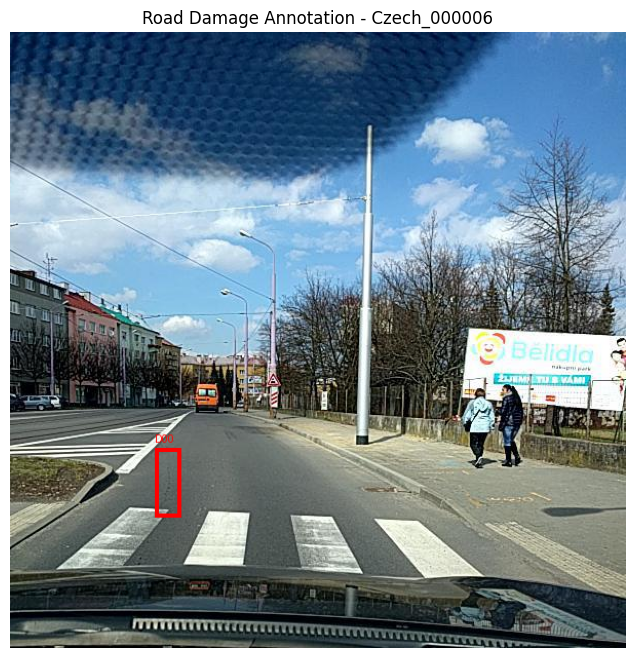

Image size: (600, 600)


In [32]:
import zipfile
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
from io import BytesIO
import matplotlib.pyplot as plt

image_id = "Czech_000006"

with zipfile.ZipFile(czech_path, "r") as z:

    # Read image
    image_path = f"Czech/train/images/{image_id}.jpg"
    image = Image.open(BytesIO(z.read(image_path))).convert("RGB")

    # Read annotation
    xml_path = f"Czech/train/annotations/xmls/{image_id}.xml"
    root = ET.fromstring(z.read(xml_path))

# Draw bounding boxes
draw = ImageDraw.Draw(image)

for obj in root.findall("object"):

    label = obj.findtext("name")
    box = obj.find("bndbox")

    xmin = int(box.findtext("xmin"))
    ymin = int(box.findtext("ymin"))
    xmax = int(box.findtext("xmax"))
    ymax = int(box.findtext("ymax"))

    draw.rectangle(
        [xmin, ymin, xmax, ymax],
        outline="red",
        width=4
    )

    draw.text(
        (xmin, max(0, ymin - 15)),
        label,
        fill="red"
    )

# Display image
plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.title(f"Road Damage Annotation - {image_id}")
plt.show()

print("Image size:", image.size)

In [33]:
from collections import Counter
import zipfile
import xml.etree.ElementTree as ET

class_counts = Counter()
images_with_damage = 0
images_without_damage = 0

with zipfile.ZipFile(czech_path, "r") as z:

    xml_files = [
        f for f in z.namelist()
        if f.endswith(".xml")
    ]

    for xml_file in xml_files:

        root = ET.fromstring(z.read(xml_file))
        objects = root.findall("object")

        if objects:
            images_with_damage += 1
        else:
            images_without_damage += 1

        for obj in objects:
            damage_type = obj.findtext("name")
            class_counts[damage_type] += 1

print("Total Annotated Images:", len(xml_files))
print("Images With Damage:", images_with_damage)
print("Images Without Damage:", images_without_damage)

print("\n=== DAMAGE DISTRIBUTION ===")

total = sum(class_counts.values())

for damage in ["D00", "D10", "D20", "D40"]:

    count = class_counts[damage]
    percentage = (count / total * 100) if total else 0

    print(f"{damage}: {count} ({percentage:.2f}%)")

print("\nTotal Bounding Boxes:", total)
print("Other Classes:", set(class_counts) - {"D00", "D10", "D20", "D40"})

Total Annotated Images: 2829
Images With Damage: 1072
Images Without Damage: 1757

=== DAMAGE DISTRIBUTION ===
D00: 988 (56.62%)
D10: 399 (22.87%)
D20: 161 (9.23%)
D40: 197 (11.29%)

Total Bounding Boxes: 1745
Other Classes: set()


In [34]:
import zipfile
from pathlib import Path

with zipfile.ZipFile(czech_path, "r") as z:

    files = z.namelist()

    # Get training image IDs
    images = {
        Path(f).stem
        for f in files
        if f.startswith("Czech/train/images/")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    # Get annotation IDs
    annotations = {
        Path(f).stem
        for f in files
        if f.startswith("Czech/train/annotations/xmls/")
        and f.endswith(".xml")
    }

    missing_annotations = images - annotations
    missing_images = annotations - images

    print("=== DATA INTEGRITY CHECK ===")
    print("Training Images:", len(images))
    print("XML Annotations:", len(annotations))
    print("Missing Annotations:", len(missing_annotations))
    print("Missing Images:", len(missing_images))

    print("\nExamples of Missing Annotations:")
    print(sorted(missing_annotations)[:5])

    print("\nExamples of Missing Images:")
    print(sorted(missing_images)[:5])

=== DATA INTEGRITY CHECK ===
Training Images: 2829
XML Annotations: 2829
Missing Annotations: 0
Missing Images: 0

Examples of Missing Annotations:
[]

Examples of Missing Images:
[]


In [35]:
import zipfile
import xml.etree.ElementTree as ET
from collections import Counter

valid_classes = {"D00", "D10", "D20", "D40"}

errors = []
class_counts = Counter()
total_boxes = 0
empty_images = 0

with zipfile.ZipFile(czech_path, "r") as z:

    xml_files = [
        f for f in z.namelist()
        if f.endswith(".xml")
    ]

    for xml_file in xml_files:
        try:
            root = ET.fromstring(z.read(xml_file))

            width = int(root.findtext("size/width"))
            height = int(root.findtext("size/height"))

            objects = root.findall("object")

            if not objects:
                empty_images += 1

            for obj in objects:
                label = obj.findtext("name")
                total_boxes += 1
                class_counts[label] += 1

                if label not in valid_classes:
                    errors.append((xml_file, "Unknown class"))

                box = obj.find("bndbox")

                xmin = float(box.findtext("xmin"))
                ymin = float(box.findtext("ymin"))
                xmax = float(box.findtext("xmax"))
                ymax = float(box.findtext("ymax"))

                if not (
                    0 <= xmin < xmax <= width
                    and 0 <= ymin < ymax <= height
                ):
                    errors.append((xml_file, "Invalid bounding box"))

        except Exception as e:
            errors.append((xml_file, str(e)))

print("=== ANNOTATION VALIDATION ===")
print("Total XML Files:", len(xml_files))
print("Total Bounding Boxes:", total_boxes)
print("Empty Annotations:", empty_images)
print("Total Errors:", len(errors))

print("\n=== CLASS COUNTS ===")
for label, count in sorted(class_counts.items()):
    print(label, count)

print("\n=== ERROR EXAMPLES ===")
for error in errors[:10]:
    print(error)

=== ANNOTATION VALIDATION ===
Total XML Files: 2829
Total Bounding Boxes: 1745
Empty Annotations: 1757
Total Errors: 0

=== CLASS COUNTS ===
D00 988
D10 399
D20 161
D40 197

=== ERROR EXAMPLES ===


In [36]:
import os
import shutil
import zipfile
from remotezip import RemoteZip

india_path = "/content/RoadScan/data/raw/India.zip"

with RemoteZip(zip_url, timeout=180) as archive:

    with archive.open("RDD2022/India.zip") as source:
        with open(india_path, "wb") as destination:
            shutil.copyfileobj(source, destination, length=1024*1024)

print("Download completed!")

print("Size (MB):", round(os.path.getsize(india_path) / 1024**2, 2))

with zipfile.ZipFile(india_path, "r") as z:

    print("Total entries:", len(z.namelist()))

    print("\nFirst 15 entries:")
    for name in z.namelist()[:15]:
        print(name)

Download completed!
Size (MB): 502.31
Total entries: 17377

First 15 entries:
India/test/
India/test/images/
India/test/images/India_000004.jpg
India/test/images/India_000006.jpg
India/test/images/India_000008.jpg
India/test/images/India_000009.jpg
India/test/images/India_000013.jpg
India/test/images/India_000015.jpg
India/test/images/India_000020.jpg
India/test/images/India_000021.jpg
India/test/images/India_000025.jpg
India/test/images/India_000029.jpg
India/test/images/India_000030.jpg
India/test/images/India_000031.jpg
India/test/images/India_000033.jpg


In [37]:
import zipfile
from pathlib import PurePosixPath

with zipfile.ZipFile(india_path, "r") as z:

    files = [
        f for f in z.namelist()
        if not f.endswith("/")
    ]

    train_images = {
        PurePosixPath(f).stem
        for f in files
        if f.startswith("India/train/images/")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    test_images = {
        PurePosixPath(f).stem
        for f in files
        if f.startswith("India/test/images/")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    annotations = {
        PurePosixPath(f).stem
        for f in files
        if f.startswith("India/train/annotations/xmls/")
        and f.lower().endswith(".xml")
    }

    print("=== INDIA DATASET ===")
    print("Training Images:", len(train_images))
    print("Test Images:", len(test_images))
    print("Annotations:", len(annotations))

    print("\n=== INTEGRITY CHECK ===")
    print("Missing Annotations:", len(train_images - annotations))
    print("Missing Images:", len(annotations - train_images))

=== INDIA DATASET ===
Training Images: 7706
Test Images: 1959
Annotations: 7706

=== INTEGRITY CHECK ===
Missing Annotations: 0
Missing Images: 0


In [38]:
import zipfile
import xml.etree.ElementTree as ET
from collections import Counter

valid_classes = {"D00", "D10", "D20", "D40"}

class_counts_india = Counter()
errors = []
empty_images = 0
total_boxes = 0

with zipfile.ZipFile(india_path, "r") as z:

    xml_files = [
        f for f in z.namelist()
        if f.startswith("India/train/annotations/xmls/")
        and f.endswith(".xml")
    ]

    for xml_file in xml_files:
        try:
            root = ET.fromstring(z.read(xml_file))

            width = int(root.findtext("size/width"))
            height = int(root.findtext("size/height"))

            objects = root.findall("object")

            if not objects:
                empty_images += 1

            for obj in objects:
                label = obj.findtext("name")
                total_boxes += 1
                class_counts_india[label] += 1

                if label not in valid_classes:
                    errors.append((xml_file, "Unknown class"))

                box = obj.find("bndbox")

                xmin = float(box.findtext("xmin"))
                ymin = float(box.findtext("ymin"))
                xmax = float(box.findtext("xmax"))
                ymax = float(box.findtext("ymax"))

                if not (
                    0 <= xmin < xmax <= width
                    and 0 <= ymin < ymax <= height
                ):
                    errors.append((xml_file, "Invalid bounding box"))

        except Exception as e:
            errors.append((xml_file, str(e)))

print("=== INDIA ANNOTATION VALIDATION ===")
print("Total Images:", len(xml_files))
print("Images With Damage:", len(xml_files) - empty_images)
print("Images Without Damage:", empty_images)
print("Total Bounding Boxes:", total_boxes)
print("Total Errors:", len(errors))

print("\n=== CLASS DISTRIBUTION ===")

for label in ["D00", "D10", "D20", "D40"]:
    count = class_counts_india[label]
    percentage = count / total_boxes * 100 if total_boxes else 0
    print(f"{label}: {count} ({percentage:.2f}%)")

print("\n=== ERROR EXAMPLES ===")
for error in errors[:10]:
    print(error)

=== INDIA ANNOTATION VALIDATION ===
Total Images: 7706
Images With Damage: 3785
Images Without Damage: 3921
Total Bounding Boxes: 8203
Total Errors: 1372

=== CLASS DISTRIBUTION ===
D00: 1555 (18.96%)
D10: 68 (0.83%)
D20: 2021 (24.64%)
D40: 3187 (38.85%)

=== ERROR EXAMPLES ===
('India/train/annotations/xmls/India_000010.xml', 'Unknown class')
('India/train/annotations/xmls/India_000014.xml', 'Unknown class')
('India/train/annotations/xmls/India_000017.xml', 'Unknown class')
('India/train/annotations/xmls/India_000032.xml', 'Unknown class')
('India/train/annotations/xmls/India_000032.xml', 'Unknown class')
('India/train/annotations/xmls/India_000038.xml', 'Unknown class')
('India/train/annotations/xmls/India_000055.xml', 'Unknown class')
('India/train/annotations/xmls/India_000055.xml', 'Unknown class')
('India/train/annotations/xmls/India_000076.xml', 'Unknown class')
('India/train/annotations/xmls/India_000078.xml', 'Unknown class')


In [39]:
required_classes = {"D00", "D10", "D20", "D40"}

print("=== ALL CLASSES IN INDIA ===")

for label, count in class_counts_india.most_common():
    print(f"{label}: {count}")

print("\n=== UNKNOWN CLASSES ===")

unknown_classes = {
    label: count
    for label, count in class_counts_india.items()
    if label not in required_classes
}

for label, count in unknown_classes.items():
    print(f"{label}: {count}")

print("\nTotal Unknown Boxes:", sum(unknown_classes.values()))

=== ALL CLASSES IN INDIA ===
D40: 3187
D20: 2021
D00: 1555
D44: 1062
D01: 179
D10: 68
D43: 57
D11: 45
D50: 28
D0w0: 1

=== UNKNOWN CLASSES ===
D44: 1062
D01: 179
D11: 45
D50: 28
D43: 57
D0w0: 1

Total Unknown Boxes: 1372


In [40]:
from collections import Counter
import zipfile
import xml.etree.ElementTree as ET

target_classes = {"D00", "D10", "D20", "D40"}
image_groups = Counter()

with zipfile.ZipFile(india_path, "r") as z:

    xml_files = [
        f for f in z.namelist()
        if f.startswith("India/train/annotations/xmls/")
        and f.endswith(".xml")
    ]

    for xml_file in xml_files:
        root = ET.fromstring(z.read(xml_file))

        labels = [
            obj.findtext("name")
            for obj in root.findall("object")
        ]

        has_target = any(
            label in target_classes for label in labels
        )

        has_extra = any(
            label not in target_classes for label in labels
        )

        if not labels:
            group = "No Boxes"

        elif has_target and has_extra:
            group = "Mixed"

        elif has_target:
            group = "Target Only"

        else:
            group = "Extra Only"

        image_groups[group] += 1

print("=== IMAGE GROUP ANALYSIS ===")

for group in ["Target Only", "Extra Only", "Mixed", "No Boxes"]:
    print(f"{group}: {image_groups[group]}")

print("\nTotal Images:", sum(image_groups.values()))

=== IMAGE GROUP ANALYSIS ===
Target Only: 2729
Extra Only: 562
Mixed: 494
No Boxes: 3921

Total Images: 7706


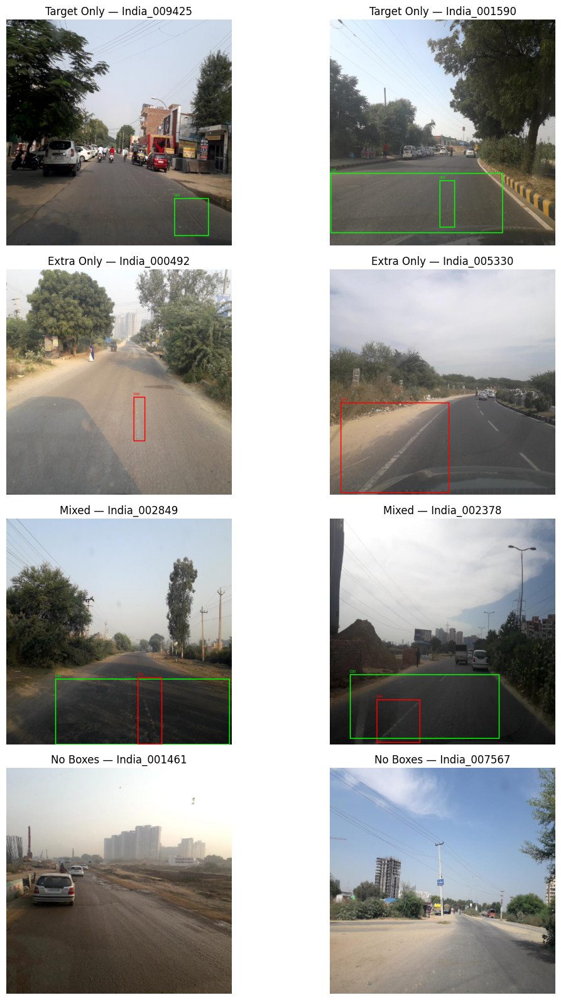

In [41]:
import random
import zipfile
import xml.etree.ElementTree as ET
from collections import defaultdict
from PIL import Image, ImageDraw
from io import BytesIO
import matplotlib.pyplot as plt

target_classes = {"D00", "D10", "D20", "D40"}
groups = defaultdict(list)

with zipfile.ZipFile(india_path, "r") as z:

    xml_files = sorted([
        f for f in z.namelist()
        if f.startswith("India/train/annotations/xmls/")
        and f.endswith(".xml")
    ])

    for xml_file in xml_files:
        root = ET.fromstring(z.read(xml_file))
        labels = [
            obj.findtext("name")
            for obj in root.findall("object")
        ]

        has_target = any(x in target_classes for x in labels)
        has_extra = any(x not in target_classes for x in labels)

        if not labels:
            group = "No Boxes"
        elif has_target and has_extra:
            group = "Mixed"
        elif has_target:
            group = "Target Only"
        else:
            group = "Extra Only"

        groups[group].append(xml_file)

    random.seed(42)

    group_names = [
        "Target Only",
        "Extra Only",
        "Mixed",
        "No Boxes"
    ]

    fig, axes = plt.subplots(4, 2, figsize=(12, 16))

    for i, group in enumerate(group_names):

        selected = random.sample(groups[group], 2)

        for j, xml_path in enumerate(selected):

            image_id = xml_path.split("/")[-1].replace(".xml", "")
            image_path = f"India/train/images/{image_id}.jpg"

            image = Image.open(
                BytesIO(z.read(image_path))
            ).convert("RGB")

            root = ET.fromstring(z.read(xml_path))
            draw = ImageDraw.Draw(image)

            for obj in root.findall("object"):

                label = obj.findtext("name")
                box = obj.find("bndbox")

                coords = [
                    int(float(box.findtext(k)))
                    for k in ["xmin", "ymin", "xmax", "ymax"]
                ]

                color = "lime" if label in target_classes else "red"

                draw.rectangle(coords, outline=color, width=3)
                draw.text(
                    (coords[0], max(0, coords[1] - 15)),
                    label,
                    fill=color
                )

            axes[i, j].imshow(image)
            axes[i, j].set_title(f"{group} — {image_id}")
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()

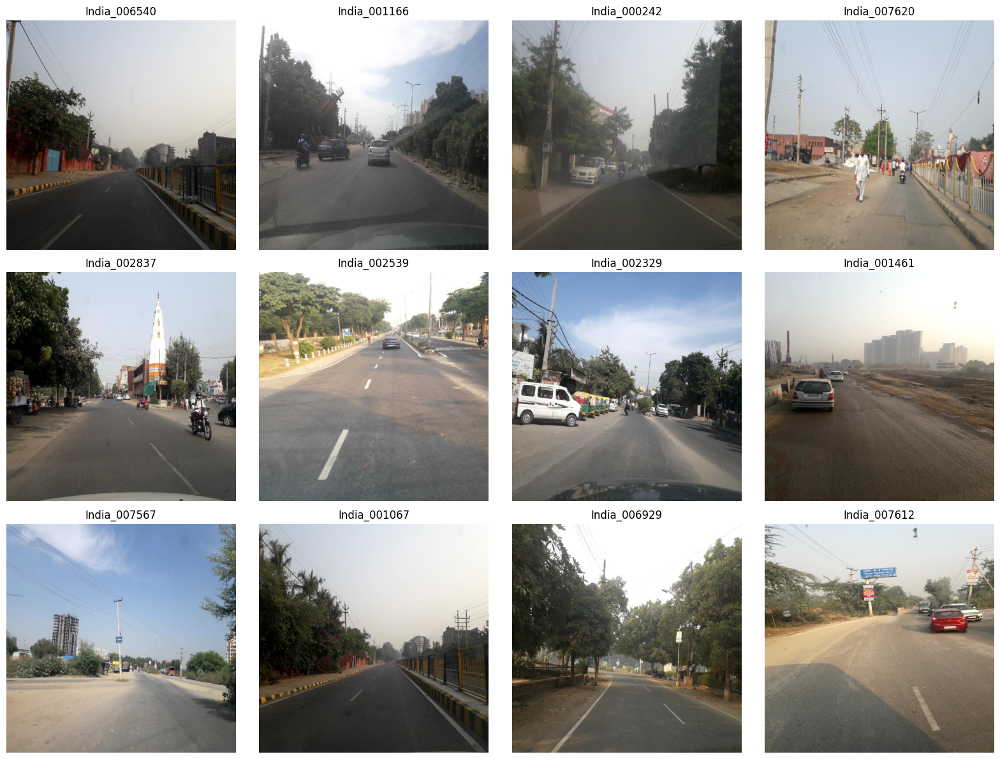

In [42]:
import random
import zipfile
from PIL import Image
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt

# Select 12 reproducible samples
selected = random.Random(42).sample(
    groups["No Boxes"], 12
)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

with zipfile.ZipFile(india_path, "r") as z:

    for ax, xml_path in zip(axes.flat, selected):

        image_id = Path(xml_path).stem
        image_path = f"India/train/images/{image_id}.jpg"

        image = Image.open(
            BytesIO(z.read(image_path))
        ).convert("RGB")

        ax.imshow(image)
        ax.set_title(image_id)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [43]:
import pandas as pd
import zipfile
import xml.etree.ElementTree as ET
from pathlib import PurePosixPath

target_classes = {"D00", "D10", "D20", "D40"}

records = []

datasets = {
    "Czech": czech_path,
    "India": india_path
}

for country, path in datasets.items():

    with zipfile.ZipFile(path, "r") as z:

        xml_files = [
            f for f in z.namelist()
            if f.startswith(f"{country}/train/annotations/xmls/")
            and f.endswith(".xml")
        ]

        for xml_file in xml_files:

            root = ET.fromstring(z.read(xml_file))

            labels = [
                obj.findtext("name")
                for obj in root.findall("object")
            ]

            target = sum(
                label in target_classes for label in labels
            )

            extra = len(labels) - target

            if target > 0 and extra == 0:
                group = "Target Only"
                status = "Candidate Positive"

            elif target == 0 and extra == 0:
                group = "No Boxes"
                status = "Candidate Negative"

            elif target > 0 and extra > 0:
                group = "Mixed"
                status = "Review"

            else:
                group = "Extra Only"
                status = "Review"

            records.append({
                "country": country,
                "image_id": PurePosixPath(xml_file).stem,
                "group": group,
                "status": status,
                "target_boxes": target,
                "extra_boxes": extra
            })

df = pd.DataFrame(records)

df.to_csv(
    "/content/RoadScan/data/manifest_v1.csv",
    index=False
)

print("=== DATA MANIFEST ===")
print(pd.crosstab(df["country"], df["group"]))

print("\n=== STATUS COUNTS ===")
print(df["status"].value_counts())

print("\nTotal Images:", len(df))

=== DATA MANIFEST ===
group    Extra Only  Mixed  No Boxes  Target Only
country                                          
Czech             0      0      1757         1072
India           562    494      3921         2729

=== STATUS COUNTS ===
status
Candidate Negative    5678
Candidate Positive    3801
Review                1056
Name: count, dtype: int64

Total Images: 10535


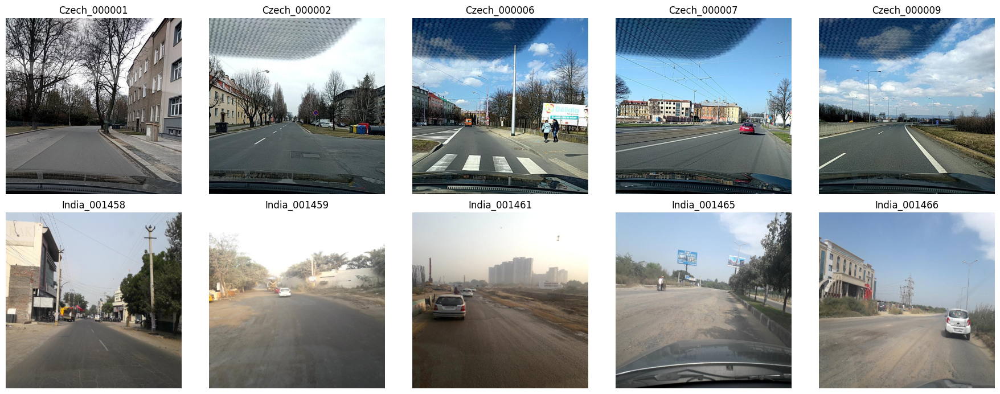

In [44]:
import zipfile
from pathlib import PurePosixPath
from PIL import Image
import matplotlib.pyplot as plt

samples = [
    ("Czech", czech_path, "Czech_000006"),
    ("India", india_path, "India_001461")
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for row, (country, path, anchor_id) in enumerate(samples):

    with zipfile.ZipFile(path, "r") as z:

        images = sorted([
            f for f in z.namelist()
            if f.startswith(f"{country}/train/images/")
            and f.lower().endswith(".jpg")
        ])

        image_ids = [PurePosixPath(f).stem for f in images]

        anchor_index = image_ids.index(anchor_id)

        start = max(0, min(anchor_index - 2, len(images) - 5))

        selected = images[start:start + 5]

        for col, image_path in enumerate(selected):

            with z.open(image_path) as file:
                image = Image.open(file).convert("RGB")

            axes[row, col].imshow(image)
            axes[row, col].set_title(
                PurePosixPath(image_path).stem
            )
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [45]:
!pip -q install ImageHash

import zipfile
import imagehash
from PIL import Image
from pathlib import PurePosixPath

datasets = {
    "Czech": czech_path,
    "India": india_path
}

similar_pairs = []

for country, path in datasets.items():

    print(f"\nChecking {country}...")

    hashes = []

    with zipfile.ZipFile(path, "r") as z:

        images = sorted([
            f for f in z.namelist()
            if f.startswith(f"{country}/train/images/")
            and f.lower().endswith(".jpg")
        ])

        for image_path in images:

            with z.open(image_path) as file:
                with Image.open(file) as image:
                    phash = imagehash.phash(image)

            image_id = PurePosixPath(image_path).stem
            hashes.append((image_id, phash))

    # Compare each image with its 10 nearest filename neighbours
    for i in range(len(hashes)):

        for j in range(i + 1, min(i + 11, len(hashes))):

            distance = hashes[i][1] - hashes[j][1]

            if distance <= 8:
                similar_pairs.append((
                    country,
                    hashes[i][0],
                    hashes[j][0],
                    distance
                ))

    print("Images checked:", len(hashes))

print("\n=== POTENTIALLY SIMILAR PAIRS ===")
print("Total pairs:", len(similar_pairs))

for pair in sorted(similar_pairs, key=lambda x: x[3])[:20]:
    print(pair)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 14.3 MB/s eta 0:00:00

Checking Czech...
Images checked: 2829

Checking India...
Images checked: 7706

=== POTENTIALLY SIMILAR PAIRS ===
Total pairs: 11
('Czech', 'Czech_001950', 'Czech_001952', 2)
('Czech', 'Czech_000271', 'Czech_000275', 8)
('Czech', 'Czech_000695', 'Czech_000698', 8)
('Czech', 'Czech_000703', 'Czech_000718', 8)
('Czech', 'Czech_001105', 'Czech_001111', 8)
('Czech', 'Czech_001114', 'Czech_001122', 8)
('Czech', 'Czech_001293', 'Czech_001299', 8)
('Czech', 'Czech_001407', 'Czech_001417', 8)
('Czech', 'Czech_002398', 'Czech_002409', 8)
('Czech', 'Czech_003276', 'Czech_003283', 8)
('India', 'India_001777', 'India_001782', 8)


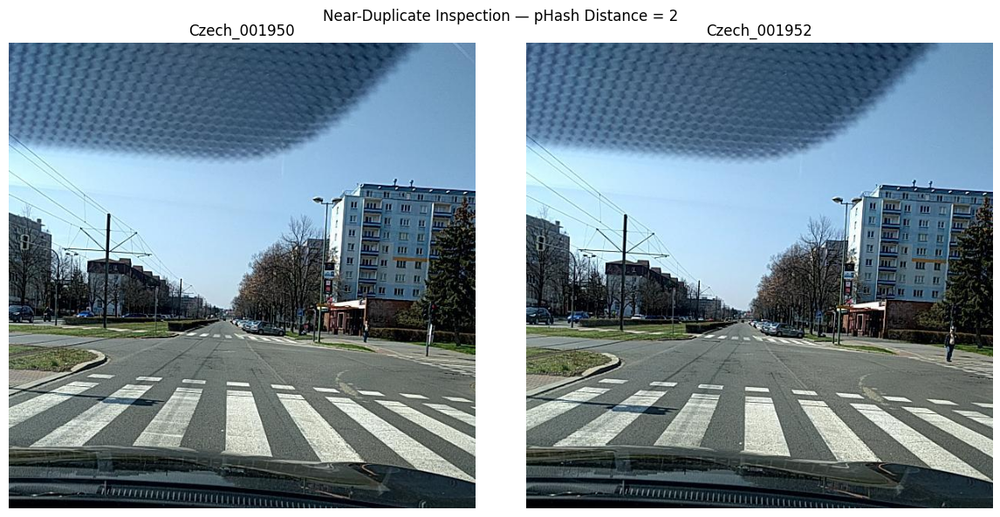

In [46]:
from PIL import Image
import matplotlib.pyplot as plt
import zipfile

image_ids = ["Czech_001950", "Czech_001952"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

with zipfile.ZipFile(czech_path, "r") as z:

    for ax, image_id in zip(axes, image_ids):

        image_path = f"Czech/train/images/{image_id}.jpg"

        with z.open(image_path) as file:
            image = Image.open(file).convert("RGB")

        ax.imshow(image)
        ax.set_title(image_id)
        ax.axis("off")

plt.suptitle("Near-Duplicate Inspection — pHash Distance = 2")
plt.tight_layout()
plt.show()

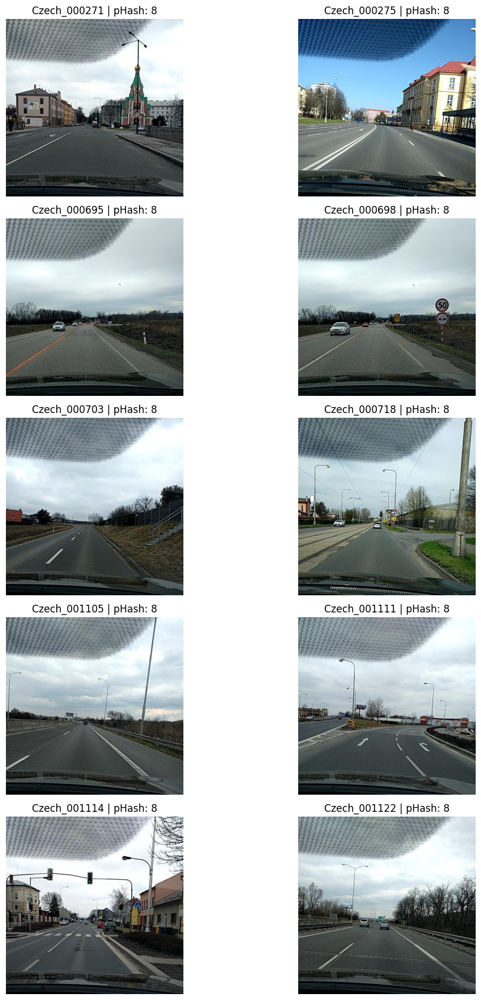

In [47]:
import zipfile
from PIL import Image
import matplotlib.pyplot as plt

# Select the next 5 similar pairs
pairs_to_check = sorted(
    similar_pairs,
    key=lambda x: x[3]
)[1:6]

fig, axes = plt.subplots(5, 2, figsize=(12, 17))

for i, (country, id1, id2, distance) in enumerate(pairs_to_check):

    path = czech_path if country == "Czech" else india_path

    with zipfile.ZipFile(path, "r") as z:

        for j, image_id in enumerate([id1, id2]):

            image_path = f"{country}/train/images/{image_id}.jpg"

            with z.open(image_path) as file:
                image = Image.open(file).convert("RGB")

            axes[i, j].imshow(image)
            axes[i, j].set_title(
                f"{image_id} | pHash: {distance}"
            )
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

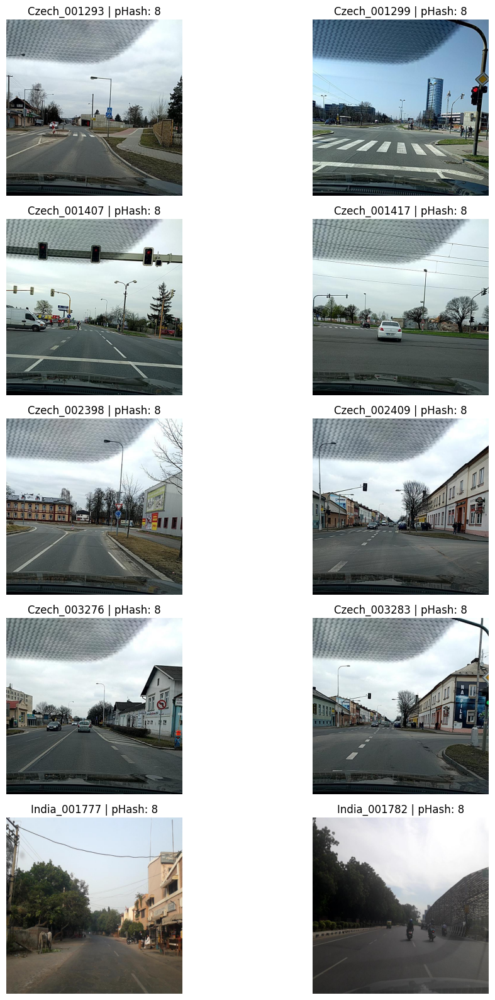

In [48]:
# Remaining 5 pairs
remaining_pairs = sorted(
    similar_pairs,
    key=lambda x: x[3]
)[6:]

fig, axes = plt.subplots(
    len(remaining_pairs), 2,
    figsize=(12, 16)
)

for i, (country, id1, id2, distance) in enumerate(remaining_pairs):

    path = czech_path if country == "Czech" else india_path

    with zipfile.ZipFile(path, "r") as z:

        for j, image_id in enumerate([id1, id2]):

            image_path = f"{country}/train/images/{image_id}.jpg"

            with z.open(image_path) as file:
                image = Image.open(file).convert("RGB")

            axes[i, j].imshow(image)
            axes[i, j].set_title(
                f"{image_id} | pHash: {distance}"
            )
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [49]:
import zipfile
import imagehash
import numpy as np
from PIL import Image
from pathlib import PurePosixPath
from sklearn.neighbors import BallTree

image_ids = []
image_hashes = []

datasets = {
    "Czech": czech_path,
    "India": india_path
}

for country, path in datasets.items():

    print(f"Processing {country}...")

    with zipfile.ZipFile(path, "r") as z:

        images = sorted([
            f for f in z.namelist()
            if f.startswith(f"{country}/train/images/")
            and f.lower().endswith(".jpg")
        ])

        for image_path in images:

            with z.open(image_path) as file:
                with Image.open(file) as image:
                    phash = imagehash.phash(
                        image.convert("RGB")
                    )

            image_ids.append(
                f"{country}/{PurePosixPath(image_path).stem}"
            )

            image_hashes.append(
                phash.hash.flatten().astype(np.uint8)
            )

# Convert hashes to an array
X = np.array(image_hashes)

print("\nTotal images:", len(X))

# Search for similar hashes across ALL images
tree = BallTree(X, metric="hamming")

neighbors = tree.query_radius(
    X,
    r=8 / 64
)

global_pairs = []

for i, matches in enumerate(neighbors):

    for j in matches:

        if j > i:

            distance = int(
                np.count_nonzero(X[i] != X[j])
            )

            global_pairs.append((
                image_ids[i],
                image_ids[j],
                distance
            ))

global_pairs.sort(key=lambda x: x[2])

print("\n=== GLOBAL SIMILARITY RESULTS ===")
print("Total Similar Pairs:", len(global_pairs))

print("\nFirst 20 Pairs:")

for pair in global_pairs[:20]:
    print(pair)

Processing Czech...
Processing India...

Total images: 10535

=== GLOBAL SIMILARITY RESULTS ===
Total Similar Pairs: 3352

First 20 Pairs:
('Czech/Czech_000618', 'Czech/Czech_001050', 0)
('Czech/Czech_002030', 'Czech/Czech_002124', 0)
('Czech/Czech_002209', 'Czech/Czech_003103', 0)
('Czech/Czech_000071', 'Czech/Czech_001746', 2)
('Czech/Czech_000298', 'Czech/Czech_003238', 2)
('Czech/Czech_000423', 'Czech/Czech_002235', 2)
('Czech/Czech_000443', 'Czech/Czech_002647', 2)
('Czech/Czech_000684', 'Czech/Czech_002342', 2)
('Czech/Czech_000771', 'Czech/Czech_001783', 2)
('Czech/Czech_000879', 'Czech/Czech_002968', 2)
('Czech/Czech_000971', 'Czech/Czech_001039', 2)
('Czech/Czech_001005', 'Czech/Czech_001669', 2)
('Czech/Czech_001039', 'Czech/Czech_001722', 2)
('Czech/Czech_001088', 'Czech/Czech_002746', 2)
('Czech/Czech_001279', 'Czech/Czech_002857', 2)
('Czech/Czech_001343', 'Czech/Czech_001578', 2)
('Czech/Czech_001408', 'Czech/Czech_002857', 2)
('Czech/Czech_001517', 'Czech/Czech_002383', 

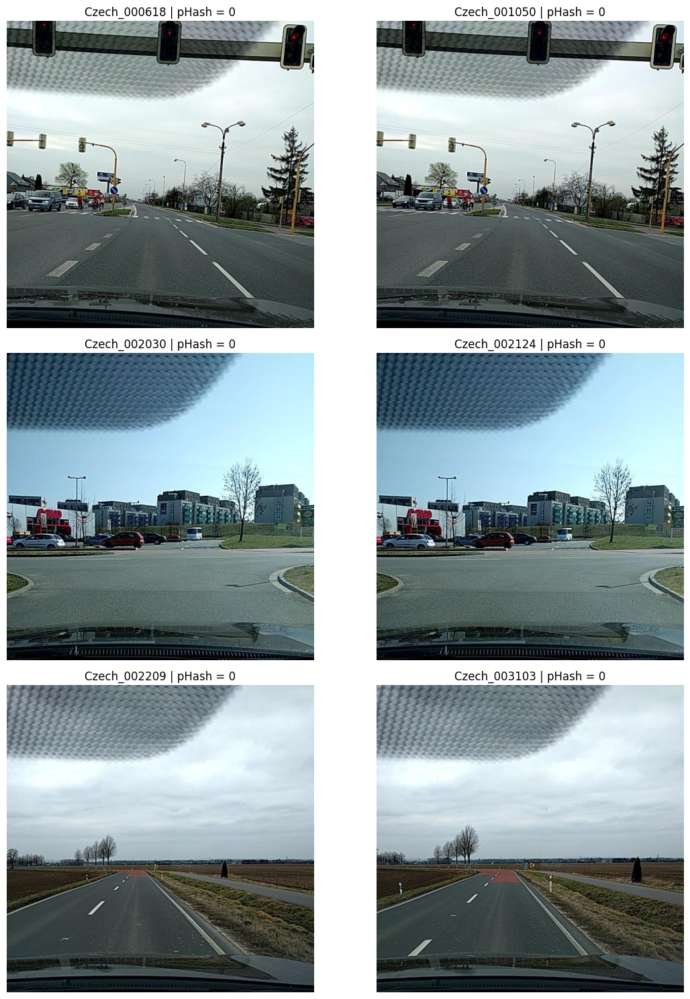

In [50]:
import zipfile
from PIL import Image
import matplotlib.pyplot as plt

# Select pairs with identical pHash
zero_pairs = [
    pair for pair in global_pairs
    if pair[2] == 0
][:3]

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

with zipfile.ZipFile(czech_path, "r") as z:

    for i, (id1, id2, distance) in enumerate(zero_pairs):

        for j, full_id in enumerate([id1, id2]):

            country, image_id = full_id.split("/")

            image_path = f"{country}/train/images/{image_id}.jpg"

            with z.open(image_path) as file:
                image = Image.open(file).convert("RGB")

            axes[i, j].imshow(image)
            axes[i, j].set_title(
                f"{image_id} | pHash = {distance}"
            )
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [51]:
import zipfile
import hashlib
import xml.etree.ElementTree as ET
from collections import Counter

pairs = [
    ("Czech_000618", "Czech_001050"),
    ("Czech_002030", "Czech_002124"),
    ("Czech_002209", "Czech_003103")
]

with zipfile.ZipFile(czech_path, "r") as z:

    for id1, id2 in pairs:

        print(f"\n=== {id1} vs {id2} ===")

        image1 = z.read(f"Czech/train/images/{id1}.jpg")
        image2 = z.read(f"Czech/train/images/{id2}.jpg")

        hash1 = hashlib.sha256(image1).hexdigest()
        hash2 = hashlib.sha256(image2).hexdigest()

        print("Exact File Duplicate:", hash1 == hash2)

        for image_id in [id1, id2]:

            xml_path = (
                f"Czech/train/annotations/xmls/"
                f"{image_id}.xml"
            )

            root = ET.fromstring(z.read(xml_path))

            labels = [
                obj.findtext("name")
                for obj in root.findall("object")
            ]

            print(image_id, "Annotations:", dict(Counter(labels)))


=== Czech_000618 vs Czech_001050 ===
Exact File Duplicate: False
Czech_000618 Annotations: {}
Czech_001050 Annotations: {}

=== Czech_002030 vs Czech_002124 ===
Exact File Duplicate: False
Czech_002030 Annotations: {}
Czech_002124 Annotations: {}

=== Czech_002209 vs Czech_003103 ===
Exact File Duplicate: False
Czech_002209 Annotations: {}
Czech_003103 Annotations: {}


In [52]:
from collections import Counter

# Count pairs by pHash distance
distance_counts = Counter(
    distance
    for _, _, distance in global_pairs
)

print("=== PHASH DISTANCE DISTRIBUTION ===")

for distance in sorted(distance_counts):
    print(f"Distance {distance}: {distance_counts[distance]} pairs")

# Strong similarity candidates
strong_pairs = [
    pair for pair in global_pairs
    if pair[2] <= 4
]

affected_images = set()

for id1, id2, distance in strong_pairs:
    affected_images.add(id1)
    affected_images.add(id2)

print("\n=== HIGH SIMILARITY CANDIDATES ===")
print("Pairs with distance <= 4:", len(strong_pairs))
print("Unique images involved:", len(affected_images))

print("\n=== CROSS-COUNTRY MATCHES ===")
cross_country = sum(
    id1.split("/")[0] != id2.split("/")[0]
    for id1, id2, _ in global_pairs
)

print("Cross-country pairs:", cross_country)

=== PHASH DISTANCE DISTRIBUTION ===
Distance 0: 3 pairs
Distance 2: 39 pairs
Distance 4: 161 pairs
Distance 6: 666 pairs
Distance 8: 2483 pairs

=== HIGH SIMILARITY CANDIDATES ===
Pairs with distance <= 4: 203
Unique images involved: 341

=== CROSS-COUNTRY MATCHES ===
Cross-country pairs: 27


=== CROSS-COUNTRY ANALYSIS ===
Total Pairs: 27

Distance Distribution:
Distance 6: 1
Distance 8: 26


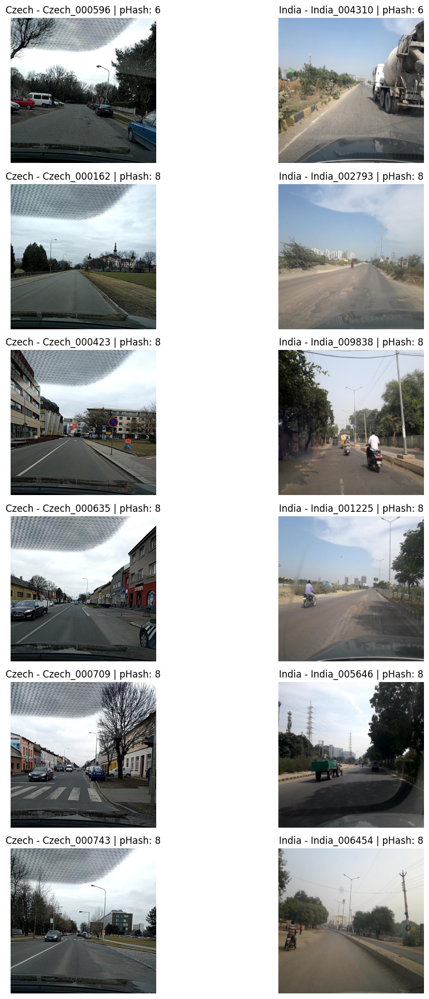

In [53]:
from collections import Counter
from contextlib import ExitStack
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt

# Find cross-country similar pairs
cross_pairs = [
    pair for pair in global_pairs
    if pair[0].split("/")[0] != pair[1].split("/")[0]
]

cross_pairs.sort(key=lambda x: x[2])

print("=== CROSS-COUNTRY ANALYSIS ===")
print("Total Pairs:", len(cross_pairs))

print("\nDistance Distribution:")
for distance, count in sorted(
    Counter(p[2] for p in cross_pairs).items()
):
    print(f"Distance {distance}: {count}")

# Display the 6 closest pairs
selected = cross_pairs[:6]

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(12, len(selected) * 3)
)

with ExitStack() as stack:
    archives = {
        "Czech": stack.enter_context(ZipFile(czech_path)),
        "India": stack.enter_context(ZipFile(india_path))
    }

    for i, (id1, id2, distance) in enumerate(selected):

        for j, full_id in enumerate([id1, id2]):
            country, image_id = full_id.split("/")

            image_path = f"{country}/train/images/{image_id}.jpg"

            image = Image.open(
                BytesIO(archives[country].read(image_path))
            ).convert("RGB")

            axes[i, j].imshow(image)
            axes[i, j].set_title(
                f"{country} - {image_id} | pHash: {distance}"
            )
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [54]:
import os
import shutil
import zipfile
from remotezip import RemoteZip

us_path = "/content/RoadScan/data/raw/United_States.zip"

# Download US dataset
with RemoteZip(zip_url, timeout=180) as archive:

    with archive.open("RDD2022/United_States.zip") as source:

        with open(us_path, "wb") as destination:

            shutil.copyfileobj(
                source,
                destination,
                length=1024 * 1024
            )

print("Download completed!")
print("Size (MB):", round(os.path.getsize(us_path) / 1024**2, 2))

# Inspect the archive
with zipfile.ZipFile(us_path, "r") as z:

    files = z.namelist()

    train_images = [
        f for f in files
        if "/train/images/" in f
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    annotations = [
        f for f in files
        if "/train/annotations/xmls/" in f
        and f.lower().endswith(".xml")
    ]

    print("\n=== US DATASET ===")
    print("Total Entries:", len(files))
    print("Training Images:", len(train_images))
    print("Annotations:", len(annotations))

    print("\nFirst 10 entries:")
    for name in files[:10]:
        print(name)

Download completed!
Size (MB): 423.75

=== US DATASET ===
Total Entries: 10816
Training Images: 4805
Annotations: 4805

First 10 entries:
United_States/test/
United_States/test/images/
United_States/test/images/United_States_004805.jpg
United_States/test/images/United_States_004806.jpg
United_States/test/images/United_States_004807.jpg
United_States/test/images/United_States_004808.jpg
United_States/test/images/United_States_004809.jpg
United_States/test/images/United_States_004810.jpg
United_States/test/images/United_States_004811.jpg
United_States/test/images/United_States_004812.jpg


In [55]:
from pathlib import Path

us_path = "/content/RoadScan/data/raw/United_States.zip"

print("File exists:", Path(us_path).exists())

if Path(us_path).exists():
    print("Size (MB):", round(Path(us_path).stat().st_size / 1024**2, 2))

File exists: True
Size (MB): 423.75


In [56]:
from pathlib import Path

data_dir = Path("/content/RoadScan/data/raw")

print("Folder Exists:", data_dir.exists())

for name in ["Czech.zip", "India.zip", "United_States.zip"]:

    path = data_dir / name

    print(f"\n{name}")
    print("Exists:", path.exists())

    if path.exists():
        print("Size (MB):", round(path.stat().st_size / 1024**2, 2))

Folder Exists: True

Czech.zip
Exists: True
Size (MB): 245.21

India.zip
Exists: True
Size (MB): 502.31

United_States.zip
Exists: True
Size (MB): 423.75


In [57]:
import zipfile
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import PurePosixPath

target_classes = {"D00", "D10", "D20", "D40"}

class_counts_us = Counter()
issues = []
empty_images = 0
total_boxes = 0

with zipfile.ZipFile(us_path, "r") as z:

    image_ids = {
        PurePosixPath(f).stem
        for f in z.namelist()
        if f.startswith("United_States/train/images/")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    xml_files = [
        f for f in z.namelist()
        if f.startswith("United_States/train/annotations/xmls/")
        and f.endswith(".xml")
    ]

    annotation_ids = {
        PurePosixPath(f).stem for f in xml_files
    }

    for xml_file in xml_files:

        try:
            root = ET.fromstring(z.read(xml_file))

            width = int(root.findtext("size/width"))
            height = int(root.findtext("size/height"))

            if width <= 0 or height <= 0:
                raise ValueError("Invalid image dimensions")

            objects = root.findall("object")

            if not objects:
                empty_images += 1

            for obj in objects:
                label = obj.findtext("name")
                class_counts_us[label] += 1
                total_boxes += 1

                box = obj.find("bndbox")

                coords = [
                    float(box.findtext(k))
                    for k in ["xmin", "ymin", "xmax", "ymax"]
                ]

                xmin, ymin, xmax, ymax = coords

                if not (
                    0 <= xmin < xmax <= width
                    and 0 <= ymin < ymax <= height
                ):
                    issues.append((xml_file, "Invalid box"))

        except Exception as e:
            issues.append((xml_file, str(e)))

print("=== US DATA INTEGRITY ===")
print("Training Images:", len(image_ids))
print("Annotations:", len(xml_files))
print("Missing XML:", len(image_ids - annotation_ids))
print("Missing Images:", len(annotation_ids - image_ids))

print("\n=== ANNOTATION VALIDATION ===")
print("Images With Boxes:", len(xml_files) - empty_images)
print("Images Without Boxes:", empty_images)
print("Total Bounding Boxes:", total_boxes)
print("Validation Issues:", len(issues))

print("\n=== CLASS DISTRIBUTION ===")
for label, count in class_counts_us.most_common():
    print(f"{label}: {count}")

print("\n=== EXTRA CLASSES ===")
for label, count in class_counts_us.items():
    if label not in target_classes:
        print(f"{label}: {count}")

print("\n=== ISSUE EXAMPLES ===")
for issue in issues[:10]:
    print(issue)

=== US DATA INTEGRITY ===
Training Images: 4805
Annotations: 4805
Missing XML: 0
Missing Images: 0

=== ANNOTATION VALIDATION ===
Images With Boxes: 4805
Images Without Boxes: 0
Total Bounding Boxes: 11014
Validation Issues: 0

=== CLASS DISTRIBUTION ===
D00: 6750
D10: 3295
D20: 834
D40: 135

=== EXTRA CLASSES ===

=== ISSUE EXAMPLES ===


In [58]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Source and destination
source = Path("/content/RoadScan/data/raw")
destination = Path("/content/drive/MyDrive/RoadScan/data/raw")

destination.mkdir(parents=True, exist_ok=True)

# Backup datasets
for name in ["Czech.zip", "India.zip", "United_States.zip"]:

    src = source / name
    dst = destination / name

    if not src.exists():
        print(f"{name}: MISSING")
        continue

    if dst.exists() and dst.stat().st_size == src.stat().st_size:
        print(f"{name}: ALREADY BACKED UP")
        continue

    shutil.copy2(src, dst)

    print(f"{name}: BACKUP COMPLETED")

# Backup the data manifest if available
manifest = Path("/content/RoadScan/data/manifest_v1.csv")

if manifest.exists():
    shutil.copy2(
        manifest,
        destination.parent / "manifest_v1.csv"
    )
    print("Data Manifest: BACKUP COMPLETED")

Mounted at /content/drive
Czech.zip: BACKUP COMPLETED
India.zip: BACKUP COMPLETED
United_States.zip: BACKUP COMPLETED
Data Manifest: BACKUP COMPLETED


=== CLASS DISTRIBUTION (%) ===
     Czech  India  United States
D00  56.62  22.76          61.29
D10  22.87   1.00          29.92
D20   9.23  29.59           7.57
D40  11.29  46.65           1.23


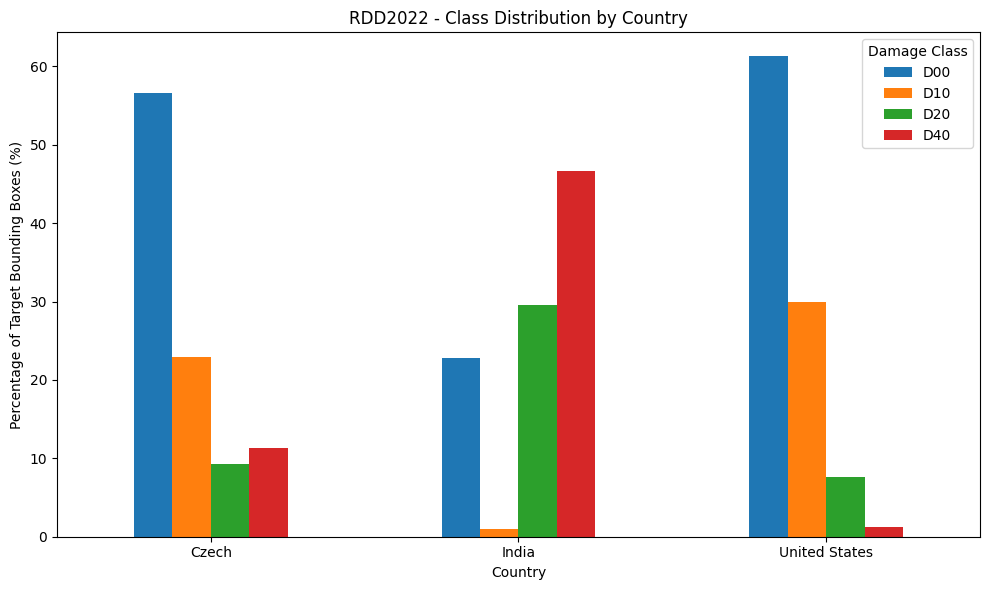

EDA results saved successfully!


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Counts from our verified EDA results
counts = pd.DataFrame({
    "Czech": [988, 399, 161, 197],
    "India": [1555, 68, 2021, 3187],
    "United States": [6750, 3295, 834, 135]
}, index=["D00", "D10", "D20", "D40"])

# Convert counts into percentages
percentages = counts.div(
    counts.sum(axis=0), axis=1
) * 100

print("=== CLASS DISTRIBUTION (%) ===")
print(percentages.round(2))

# Visual comparison
ax = percentages.T.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("RDD2022 - Class Distribution by Country")
ax.set_xlabel("Country")
ax.set_ylabel("Percentage of Target Bounding Boxes (%)")
ax.legend(title="Damage Class")

plt.xticks(rotation=0)
plt.tight_layout()

# Save EDA results to Google Drive
output_dir = Path(
    "/content/drive/MyDrive/RoadScan/results/eda"
)
output_dir.mkdir(parents=True, exist_ok=True)

counts.to_csv(output_dir / "class_counts.csv")
percentages.to_csv(
    output_dir / "class_percentages.csv"
)

plt.savefig(
    output_dir / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("EDA results saved successfully!")

In [60]:
import requests

url = "https://api.figshare.com/v2/articles/21431547"

response = requests.get(url, timeout=30)
response.raise_for_status()

metadata = response.json()

print("=== RDD2022 OFFICIAL METADATA ===")
print("Title:", metadata.get("title"))
print("DOI:", metadata.get("doi"))
print("Published:", metadata.get("published_date"))

license_info = metadata.get("license")

if isinstance(license_info, dict):
    print("License:", license_info.get("name"))
    print("License URL:", license_info.get("url"))
else:
    print("License:", license_info)

print("Source:", metadata.get("url_public_html"))

=== RDD2022 OFFICIAL METADATA ===
Title: RDD2022 - The multi-national Road Damage Dataset released through CRDDC'2022
DOI: 10.6084/m9.figshare.21431547.v1
Published: 2022-10-29T10:53:29Z
License: CC BY 4.0
License URL: https://creativecommons.org/licenses/by/4.0/
Source: https://figshare.com/articles/dataset/RDD2022_-_The_multi-national_Road_Damage_Dataset_released_through_CRDDC_2022/21431547


data card later

![{F7BB6A02-8C21-455D-BA47-2966F15E1181}.png]()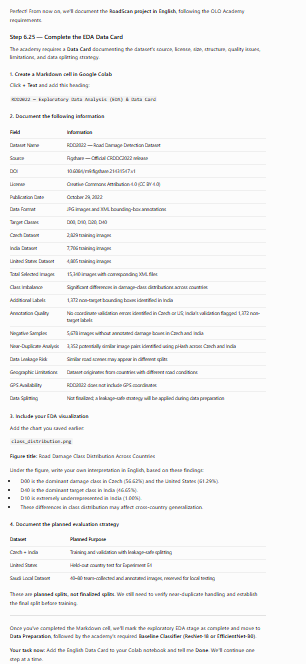